# TRỰC QUAN HÓA VÀ PHÂN TÍCH DỮ LIỆU KHÁCH HÀNG TRONG HOẠT ĐỘNG MARKETING

<a id="phan-1"></a>
## 1. GIỚI THIỆU VÀ MỤC TIÊU PHÂN TÍCH



**Các câu hỏi phân tích:**

- Khách hàng có đặc điểm tuổi, học vấn và tình trạng hôn nhân như thế nào?
- Chi tiêu phân bổ vào sáu nhóm sản phẩm và lượt mua phân bổ qua ba kênh ra sao?
- Tỷ lệ chấp nhận chiến dịch và phản hồi theo mức chi tiêu khác nhau như thế nào?
- Thu nhập và tổng chi tiêu có mối liên hệ gì trong mẫu?


**Luồng thực hiện:** xác định câu hỏi → đọc CSV → làm sạch → tạo thuộc tính và chỉ số → vẽ biểu đồ → dashboard tự cập nhật.

Notebook xuất `marketing_clean_powerbi.csv` ngay trong thư mục này. Dashboard ở thư mục `Tai_lieu_kem_theo/dashboard_streamlit` đọc chính tệp đó



# MỤC LỤC

1. [Giới thiệu và mục tiêu phân tích](#phan-1)
2. [Nhập các thư viện](#phan-2)
3. [Nạp và tìm hiểu dữ liệu](#phan-3)
   - [3.1. Nạp dữ liệu](#phan-3-1)
   - [3.2. Tổng quan dữ liệu](#phan-3-2)
   - [3.3. Kiểm tra chất lượng dữ liệu](#phan-3-3)
4. [Làm sạch dữ liệu và tạo thuộc tính](#phan-4)
   - [4.1. Xử lý giá trị thiếu](#phan-4-1)
   - [4.2. Kiểm tra và loại bản ghi bất thường](#phan-4-2)
   - [4.3. Tạo thuộc tính và nhóm chi tiêu](#phan-4-3)
   - [4.4. Kiểm tra dữ liệu sau làm sạch](#phan-4-4)
   - [4.5. Các chỉ số tổng quan](#phan-4-5)
5. [Phân tích khám phá và trực quan hóa](#phan-5)
   - [5.1. Chi tiêu theo sản phẩm](#phan-5-1)
   - [5.2. Phản hồi và chấp nhận chiến dịch](#phan-5-2)
   - [5.3. Lượt mua theo kênh](#phan-5-3)
   - [5.4. Hồ sơ khách hàng](#phan-5-4)
   - [5.5. Thu nhập và tổng chi tiêu](#phan-5-5)
6. [So sánh nhóm chi tiêu và đề xuất marketing](#phan-6)
   - [6.1. Quy mô, khoảng chi tiêu và phản hồi](#phan-6-1)
   - [6.2. Đặc điểm từng nhóm](#phan-6-2)
   - [6.3. Hướng thử nghiệm marketing](#phan-6-3)
7. [Xuất và đối chiếu dữ liệu cho dashboard](#phan-7)
   - [7.1. Lựa chọn thuộc tính xuất](#phan-7-1)
   - [7.2. Đối chiếu số liệu với báo cáo](#phan-7-2)
8. [Kết luận và hạn chế](#phan-8)

<a id="phan-2"></a>
# 2. NHẬP CÁC THƯ VIỆN

Pandas dùng để xử lý bảng dữ liệu; Matplotlib dùng để vẽ biểu đồ.
Các danh sách cột, nhãn và màu được khai báo một lần để dùng ở các mục sau.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

product_columns = [
    "MntWines", "MntFruits", "MntMeatProducts",
    "MntFishProducts", "MntSweetProducts", "MntGoldProds",
]
purchase_columns = ["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]
campaign_columns = ["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3", "AcceptedCmp4", "AcceptedCmp5"]
group_names = ["Chi tiêu thấp", "Chi tiêu trung bình", "Chi tiêu cao"]
group_colors = ["#6BAED6", "#FDAE6B", "#4C9F70"]
product_labels = {
    "MntWines": "Rượu vang", "MntFruits": "Trái cây", "MntMeatProducts": "Thịt",
    "MntFishProducts": "Cá", "MntSweetProducts": "Đồ ngọt", "MntGoldProds": "Gold (nhãn nguồn)",
}
channel_labels = {
    "NumWebPurchases": "Web", "NumCatalogPurchases": "Catalog", "NumStorePurchases": "Cửa hàng",
}

<a id="phan-3"></a>
# 3. NẠP VÀ TÌM HIỂU DỮ LIỆU

<a id="phan-3-1"></a>
## 3.1. NẠP DỮ LIỆU


In [ ]:
df_raw = pd.read_csv("marketing_campaign.csv", sep="\t")

<a id="phan-3-2"></a>
## 3.2. TỔNG QUAN DỮ LIỆU

Mỗi dòng là một khách hàng. Xem dữ liệu mẫu và kích thước bảng trước khi xử lý.
`Dt_Customer` là ngày gia nhập, không phải ngày giao dịch hoặc ngày thực hiện chiến dịch.

In [ ]:
display(df_raw.head())
print("Số dòng và số cột ban đầu:", df_raw.shape)

join_dates = pd.to_datetime(df_raw["Dt_Customer"], dayfirst=True)
print("Khoảng ngày gia nhập:", join_dates.min().strftime("%d/%m/%Y"), "đến", join_dates.max().strftime("%d/%m/%Y"))

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0


Số dòng và số cột ban đầu: (2240, 29)
Khoảng ngày gia nhập: 30/07/2012 đến 29/06/2014


<a id="phan-3-3"></a>
## 3.3. KIỂM TRA CHẤT LƯỢNG DỮ LIỆU

### Các nhóm biến chính

| Nhóm thông tin | Các cột tiêu biểu | Ý nghĩa |
|---|---|---|
| Hồ sơ khách hàng | `ID`, `Year_Birth`, `Education`, `Marital_Status`, `Income` | Đặc điểm định danh và nhân khẩu học |
| Thành phần hộ gia đình | `Kidhome`, `Teenhome` | Số trẻ nhỏ và thanh thiếu niên trong hộ |
| Chi tiêu sản phẩm | `MntWines`, `MntFruits`, `MntMeatProducts`, `MntFishProducts`, `MntSweetProducts`, `MntGoldProds` | Tổng chi tiêu theo từng nhóm sản phẩm |
| Hành vi mua hàng | `NumWebPurchases`, `NumCatalogPurchases`, `NumStorePurchases`, `NumDealsPurchases`, `NumWebVisitsMonth` | Số lượt mua, khuyến mãi và truy cập web |
| Phản hồi chiến dịch | `AcceptedCmp1`–`AcceptedCmp5`, `Response`, `Complain` | Trạng thái chấp nhận chiến dịch và khiếu nại |
| Thời gian | `Dt_Customer`, `Recency` | Ngày gia nhập và số ngày kể từ lần mua gần nhất |


In [ ]:
quality_before = pd.DataFrame({
    "Kiểu dữ liệu": df_raw.dtypes.astype(str),
    "Số ô thiếu": df_raw.isna().sum(),
    "Số giá trị khác nhau": df_raw.nunique(dropna=False),
})
display(quality_before)
print("ID bị trùng:", df_raw["ID"].duplicated().sum())
print("Dòng trùng hoàn toàn:", df_raw.duplicated().sum())
print("Các cột hằng:", df_raw.columns[df_raw.nunique(dropna=False) == 1].tolist())

,Kiểu dữ liệu,Số ô thiếu,Số giá trị khác nhau
ID,int64,0,2240
Year_Birth,int64,0,59
Education,str,0,5
Marital_Status,str,0,8
Income,float64,24,1975
Kidhome,int64,0,3
Teenhome,int64,0,3
Dt_Customer,str,0,663
Recency,int64,0,100
MntWines,int64,0,776


ID bị trùng: 0
Dòng trùng hoàn toàn: 0
Các cột hằng: ['Z_CostContact', 'Z_Revenue']


<a id="phan-4"></a>
# 4. LÀM SẠCH DỮ LIỆU VÀ TẠO THUỘC TÍNH

Thực hiện theo thứ tự: điền thu nhập thiếu, lọc bất thường, tạo thuộc tính, chia nhóm chi tiêu.
`df_raw` giữ dữ liệu gốc; `df_imputed` lưu bước điền thu nhập; `df_clean` lưu dữ liệu sau lọc.

<a id="phan-4-1"></a>
## 4.1. XỬ LÝ GIÁ TRỊ THIẾU

Điền `Income` thiếu bằng trung vị thu nhập của những người có cùng `Education`.
`transform("median")` trả lại trung vị tương ứng cho từng dòng; `fillna()` chỉ thay ô thiếu.
Ví dụ, hồ sơ Graduation thiếu thu nhập được điền bằng trung vị của nhóm Graduation.
Giá trị điền là ước lượng, không phải thu nhập thực đã được xác minh.

In [ ]:
income_groups = df_raw.groupby("Education")["Income"]
income_summary = pd.DataFrame({
    "Trung vị Income": income_groups.median(),
    "Số Income thiếu": income_groups.size() - income_groups.count(),
})
display(income_summary[income_summary["Số Income thiếu"] > 0])

df_imputed = df_raw.copy()
df_imputed["Income"] = df_imputed["Income"].fillna(income_groups.transform("median"))
print("Income thiếu trước/sau:", df_raw["Income"].isna().sum(), df_imputed["Income"].isna().sum())

,Trung vị Income,Số Income thiếu
Education,,
2n Cycle,46805.0,3
Graduation,52028.5,11
Master,50943.0,5
PhD,55212.0,5


Income thiếu trước/sau: 24 0


<a id="phan-4-2"></a>
## 4.2. KIỂM TRA VÀ LOẠI BẢN GHI BẤT THƯỜNG

Tính `Age = 2014 - Year_Birth`, rồi giữ tuổi từ 18 đến 89 và `Income < 600000`.
`&` nghĩa là phải thỏa cả hai điều kiện; `~` đảo điều kiện để xem các hồ sơ bị loại.
Đây là quy tắc làm sạch của bài. Tuổi được tính tại năm 2014; các thu nhập cao khác vẫn giữ nếu hợp lệ.

In [ ]:
df_clean = df_imputed.copy()
df_clean["Age"] = 2014 - df_clean["Year_Birth"]

valid_age = df_clean["Age"].between(18, 89)
valid_income = df_clean["Income"] < 600000
outliers = df_clean.loc[~(valid_age & valid_income), ["ID", "Year_Birth", "Age", "Income"]]
display(outliers)

df_clean = df_clean[valid_age & valid_income].copy()
print("Số hồ sơ đã loại/còn lại:", len(outliers), len(df_clean))

,ID,Year_Birth,Age,Income
192,7829,1900,114,36640.0
239,11004,1893,121,60182.0
339,1150,1899,115,83532.0
2233,9432,1977,37,666666.0


Số hồ sơ đã loại/còn lại: 4 2236


<a id="phan-4-3"></a>
## 4.3. TẠO THUỘC TÍNH VÀ NHÓM CHI TIÊU

### 4.3.1. Tạo thuộc tính

`Children` cộng số trẻ nhỏ và thanh thiếu niên trong hộ.
`Is_Parent` bằng 1 khi `Children > 0`, còn lại bằng 0.
`Spent` cộng sáu cột sản phẩm trên từng dòng; `axis=1` nghĩa là cộng theo hàng.

In [ ]:
df_clean["Children"] = df_clean["Kidhome"] + df_clean["Teenhome"]
df_clean["Is_Parent"] = (df_clean["Children"] > 0).astype(int)
df_clean["Spent"] = df_clean[product_columns].sum(axis=1)

display(df_clean[["ID", "Children", "Is_Parent", "Spent"]].head())

,ID,Children,Is_Parent,Spent
0,5524,0,0,1617
1,2174,2,1,27
2,4141,0,0,776
3,6182,1,1,53
4,5324,1,1,422


### 4.3.2. Chia ba nhóm chi tiêu

`qcut(..., q=3)` chia theo phân vị: mỗi nhóm có khoảng một phần ba số khách hàng.
Các mốc được tính từ `Spent`, nên không ghi cố định ngưỡng vào điều kiện.
Đây là phân nhóm mô tả theo chi tiêu. Hai cột hằng được bỏ khỏi bảng phân tích.
Bảng bên dưới cho biết khoảng chi tiêu và quy mô thực tế của từng nhóm.

In [ ]:
df_clean["Spending_Group"] = pd.qcut(df_clean["Spent"], q=3, labels=group_names)
df_clean = df_clean.drop(columns=["Z_CostContact", "Z_Revenue"], errors="ignore")

spending_ranges = df_clean.groupby("Spending_Group", observed=True)["Spent"].agg(["min", "max", "count"])
spending_ranges.columns = ["Chi tiêu thấp nhất", "Chi tiêu cao nhất", "Số khách hàng"]
display(spending_ranges)

,Chi tiêu thấp nhất,Chi tiêu cao nhất,Số khách hàng
Spending_Group,,,
Chi tiêu thấp,5,115,746
Chi tiêu trung bình,116,832,745
Chi tiêu cao,833,2525,745


<a id="phan-4-4"></a>
## 4.4. KIỂM TRA DỮ LIỆU SAU LÀM SẠCH

Kiểm tra ô thiếu, ID, giới hạn tuổi và thu nhập, giá trị không âm, biến 0/1, tổng chi tiêu và nhóm.
Mỗi dòng trong bảng trả về `True` khi đạt; `assert` dừng chương trình nếu có kiểm tra chưa đạt.

In [ ]:
binary_columns = campaign_columns + ["Response", "Is_Parent"]
checks = pd.Series({
    "Không còn ô thiếu": df_clean.notna().all().all(),
    "ID không thiếu và duy nhất": df_clean["ID"].notna().all() and df_clean["ID"].is_unique,
    "Tuổi nằm trong 18–89": df_clean["Age"].between(18, 89).all(),
    "Income không âm và dưới 600.000": df_clean["Income"].between(0, 600000, inclusive="left").all(),
    "Chi tiêu và lượt mua không âm": (df_clean[product_columns + purchase_columns] >= 0).all().all(),
    "Các trường nhị phân chỉ nhận 0 hoặc 1": df_clean[binary_columns].isin([0, 1]).all().all(),
    "Spent bằng tổng sáu cột sản phẩm": (df_clean["Spent"] == df_clean[product_columns].sum(axis=1)).all(),
    "Nhóm chi tiêu được tạo đầy đủ": df_clean["Spending_Group"].notna().all(),
}, name="Đạt kiểm tra")
display(checks.to_frame())
assert checks.all(), "Có kiểm tra dữ liệu chưa đạt."

,Đạt kiểm tra
Không còn ô thiếu,True
ID không thiếu và duy nhất,True
Tuổi nằm trong 18–89,True
Income không âm và dưới 600.000,True
Chi tiêu và lượt mua không âm,True
Các trường nhị phân chỉ nhận 0 hoặc 1,True
Spent bằng tổng sáu cột sản phẩm,True
Nhóm chi tiêu được tạo đầy đủ,True


<a id="phan-4-5"></a>
## 4.5. CÁC CHỈ SỐ TỔNG QUAN

Bốn chỉ số tương ứng các thẻ KPI trên toàn bộ dữ liệu sạch.
`Response` có giá trị 0/1, nên `mean() * 100` cho tỷ lệ khách hàng có phản hồi.

In [ ]:
kpi_summary = pd.DataFrame([
    ["Số khách hàng", len(df_clean), "Khách hàng"],
    ["Tổng chi tiêu", df_clean["Spent"].sum(), "ĐVTT"],
    ["Thu nhập trung bình", df_clean["Income"].mean(), "ĐVTT"],
    ["Tỷ lệ phản hồi gần nhất", df_clean["Response"].mean() * 100, "%"],
], columns=["Chỉ số", "Giá trị", "Đơn vị"])
display(kpi_summary.round(2))
print("Số khách hàng phản hồi:", df_clean["Response"].sum())

,Chỉ số,Giá trị,Đơn vị
0,Số khách hàng,2236.00,Khách hàng
1,Tổng chi tiêu,1354986.00,ĐVTT
2,Thu nhập trung bình,51957.24,ĐVTT
3,Tỷ lệ phản hồi gần nhất,14.94,%


Số khách hàng phản hồi: 334


<a id="phan-5"></a>
# 5. PHÂN TÍCH KHÁM PHÁ VÀ TRỰC QUAN HÓA

Các bảng và biểu đồ trả lời những câu hỏi đã đặt ra, đồng thời cung cấp số liệu đối chiếu cho Power BI. Chi tiêu sử dụng đơn vị tiền tệ của dữ liệu; không tự gán loại tiền khi nguồn chưa xác định.

<a id="phan-5-1"></a>
## 5.1. CHI TIÊU THEO NHÓM SẢN PHẨM

Thanh ngang so sánh tổng chi tiêu của sáu nhóm sản phẩm; bảng kèm theo cung cấp tỷ trọng trong tổng Spent. Giữ nhãn Gold theo trường nguồn vì chưa có thông tin xác nhận danh mục kinh doanh cụ thể. Tổng chi tiêu không đồng nghĩa với số lượng sản phẩm hoặc lợi nhuận.

In [ ]:
product_totals = df_clean[product_columns].sum().sort_values(ascending=False)
product_summary = pd.DataFrame({
    "Tổng chi tiêu (ĐVTT)": product_totals,
    "Tỷ trọng (%)": product_totals / product_totals.sum() * 100,
}).rename(index=product_labels)
display(product_summary.round(2))

,Tổng chi tiêu (ĐVTT),Tỷ trọng (%)
Rượu vang,680029,50.19
Thịt,373375,27.56
Gold (nhãn nguồn),98346,7.26
Cá,83931,6.19
Đồ ngọt,60552,4.47
Trái cây,58753,4.34


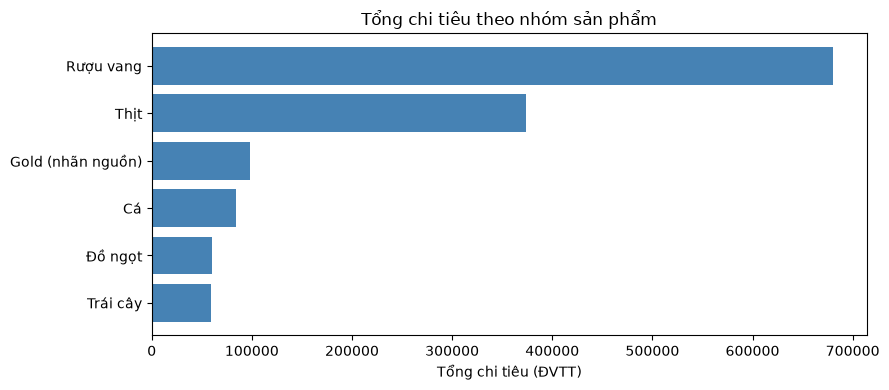

In [ ]:
values = product_summary["Tổng chi tiêu (ĐVTT)"].sort_values()
plt.figure(figsize=(9, 4))
plt.barh(values.index, values.values, color="steelblue")
plt.title("Tổng chi tiêu theo nhóm sản phẩm")
plt.xlabel("Tổng chi tiêu (ĐVTT)")
plt.tight_layout()
plt.show()

**Nhận xét:** Rượu vang có tổng chi tiêu 680.029 ĐVTT, chiếm 50,19%; thịt đứng thứ hai với 27,56%. Hai nhóm này đóng góp phần lớn chi tiêu của mẫu.

<a id="phan-5-2"></a>
## 5.2. PHẢN HỒI VÀ CHẤP NHẬN CHIẾN DỊCH
Biểu đồ vành khuyên thể hiện hai trạng thái `Response`; cột so sánh năm trường `AcceptedCmp`.
`plt.subplot(1, 2, 1)` chọn hình bên trái, `plt.subplot(1, 2, 2)` chọn hình bên phải.

Tỷ lệ tính trên toàn bộ khách hàng sạch vì chưa có số người thực sự được tiếp cận.
Một khách hàng có thể chấp nhận nhiều chiến dịch, nên các tỷ lệ AcceptedCmp không tạo thành cơ cấu 100%.
Tỷ lệ cao hơn chưa đủ để kết luận hiệu quả tài chính tốt hơn.

In [ ]:
campaign_fields = campaign_columns + ["Response"]
campaign_summary = pd.DataFrame({
    "Số khách hàng chấp nhận/phản hồi": df_clean[campaign_fields].sum(),
    "Tỷ lệ trên toàn bộ mẫu (%)": df_clean[campaign_fields].mean() * 100,
})
campaign_summary.index = [
    "Chiến dịch 1", "Chiến dịch 2", "Chiến dịch 3",
    "Chiến dịch 4", "Chiến dịch 5", "Chiến dịch gần nhất (Response)",
]
display(campaign_summary.round(2))

,Số khách hàng chấp nhận/phản hồi,Tỷ lệ trên toàn bộ mẫu (%)
Chiến dịch 1,144,6.44
Chiến dịch 2,30,1.34
Chiến dịch 3,163,7.29
Chiến dịch 4,167,7.47
Chiến dịch 5,162,7.25
Chiến dịch gần nhất (Response),334,14.94


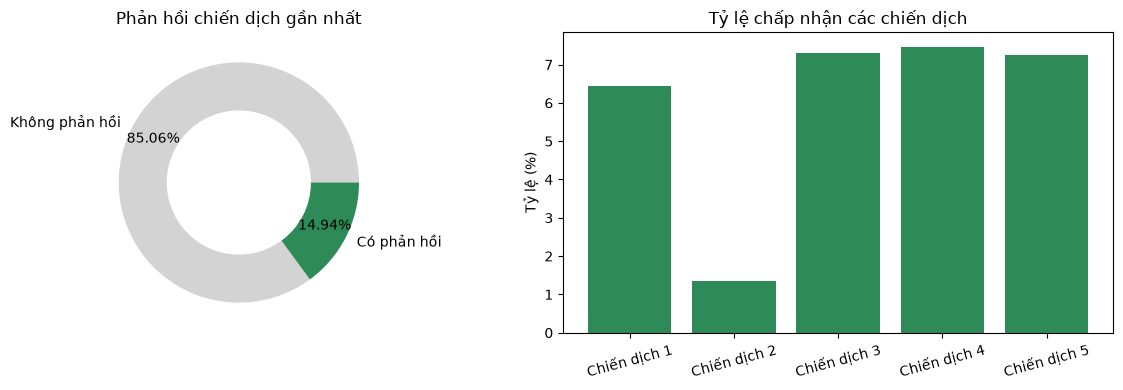

In [ ]:
response_counts = df_clean["Response"].value_counts().reindex([0, 1], fill_value=0)
campaign_rates = campaign_summary.iloc[:5]["Tỷ lệ trên toàn bộ mẫu (%)"]
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.pie(response_counts, labels=["Không phản hồi", "Có phản hồi"],
        colors=["lightgray", "seagreen"], autopct="%1.2f%%",
        pctdistance=0.8, wedgeprops={"width": 0.4})
plt.title("Phản hồi chiến dịch gần nhất")

plt.subplot(1, 2, 2)
plt.bar(campaign_rates.index, campaign_rates.values, color="seagreen")
plt.title("Tỷ lệ chấp nhận các chiến dịch")
plt.ylabel("Tỷ lệ (%)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**Nhận xét:** Có 334 khách hàng phản hồi chiến dịch gần nhất, tương ứng 14,94%. Trong AcceptedCmp1–5, chiến dịch 4 có tỷ lệ chấp nhận cao nhất (7,47%), chiến dịch 2 thấp nhất (1,34%).

<a id="phan-5-3"></a>
## 5.3. HÀNH VI MUA HÀNG THEO KÊNH

So sánh tổng lượt mua qua Web, Catalog và Store. `NumDealsPurchases` là số lượt mua có khuyến mãi, không phải một kênh riêng; `NumWebVisitsMonth` là lượt truy cập, không phải lượt mua.


In [ ]:
channel_totals = df_clean[purchase_columns].sum().sort_values(ascending=False)
channel_summary = pd.DataFrame({
    "Tổng lượt mua": channel_totals,
    "Tỷ trọng (%)": channel_totals / channel_totals.sum() * 100,
    "Lượt mua TB mỗi khách hàng": channel_totals / len(df_clean),
}).rename(index=channel_labels)
display(channel_summary.round(2))

,Tổng lượt mua,Tỷ trọng (%),Lượt mua TB mỗi khách hàng
Cửa hàng,12959,46.19,5.80
Web,9140,32.58,4.09
Catalog,5955,21.23,2.66


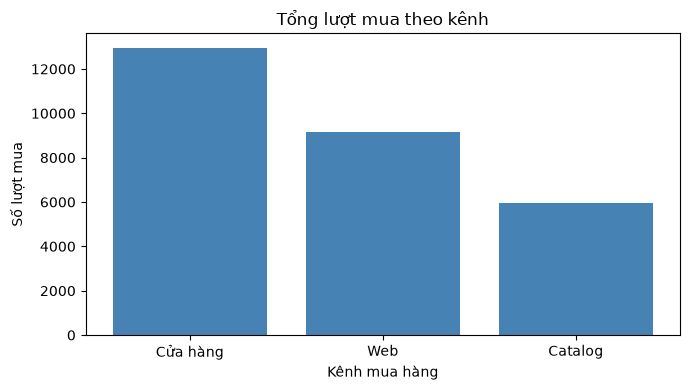

In [ ]:
values = channel_summary["Tổng lượt mua"]
plt.figure(figsize=(7, 4))
plt.bar(values.index, values.values, color="steelblue")
plt.title("Tổng lượt mua theo kênh")
plt.xlabel("Kênh mua hàng")
plt.ylabel("Số lượt mua")
plt.tight_layout()
plt.show()

**Nhận xét:** Tổng lượt mua qua ba kênh là 28.054. Cửa hàng chiếm 46,19%, Web 32,58% và Catalog 21,23%; đây là tỷ trọng lượt mua.

<a id="phan-5-4"></a>
## 5.4. HỒ SƠ KHÁCH HÀNG

Mô tả tuổi tại năm 2014, học vấn và hôn nhân. `value_counts()` đếm số khách hàng ở mỗi giá trị.
Bảng khoảng tuổi dùng `cut()` với các mốc đã chọn; biểu đồ tuổi vẫn vẽ từng tuổi.
Các nhãn hiếm như Alone, Absurd và YOLO được giữ theo nguồn.

In [ ]:
age_groups = pd.cut(df_clean["Age"], bins=[17, 24, 34, 49, 64, 89],
                    labels=["18–24", "25–34", "35–49", "50–64", "65 tuổi trở lên"])
age_counts = age_groups.value_counts(sort=False)
age_summary = pd.DataFrame({
    "Số khách hàng": age_counts,
    "Tỷ trọng (%)": age_counts / len(df_clean) * 100,
})
display(age_summary.round(2))
print("Tuổi thấp nhất/cao nhất:", df_clean["Age"].min(), df_clean["Age"].max())
print("Tuổi trung bình/trung vị:", round(df_clean["Age"].mean(), 2), df_clean["Age"].median())

age_distribution = df_clean["Age"].value_counts().sort_index()
education_counts = df_clean["Education"].value_counts()
marital_counts = df_clean["Marital_Status"].value_counts()
for title, counts in [("Học vấn", education_counts), ("Tình trạng hôn nhân", marital_counts)]:
    print(title)
    display(pd.DataFrame({"Số khách hàng": counts, "Tỷ trọng (%)": counts / len(df_clean) * 100}).round(2))

,Số khách hàng,Tỷ trọng (%)
Age,,
18–24,61,2.73
25–34,363,16.23
35–49,1029,46.02
50–64,676,30.23
65 tuổi trở lên,107,4.79


Tuổi thấp nhất/cao nhất: 18 74
Tuổi trung bình/trung vị: 45.1 44.0
Học vấn


,Số khách hàng,Tỷ trọng (%)
Education,,
Graduation,1126,50.36
PhD,485,21.69
Master,370,16.55
2n Cycle,201,8.99
Basic,54,2.42


Tình trạng hôn nhân


,Số khách hàng,Tỷ trọng (%)
Marital_Status,,
Married,864,38.64
Together,578,25.85
Single,479,21.42
Divorced,231,10.33
Widow,77,3.44
Alone,3,0.13
Absurd,2,0.09
YOLO,2,0.09


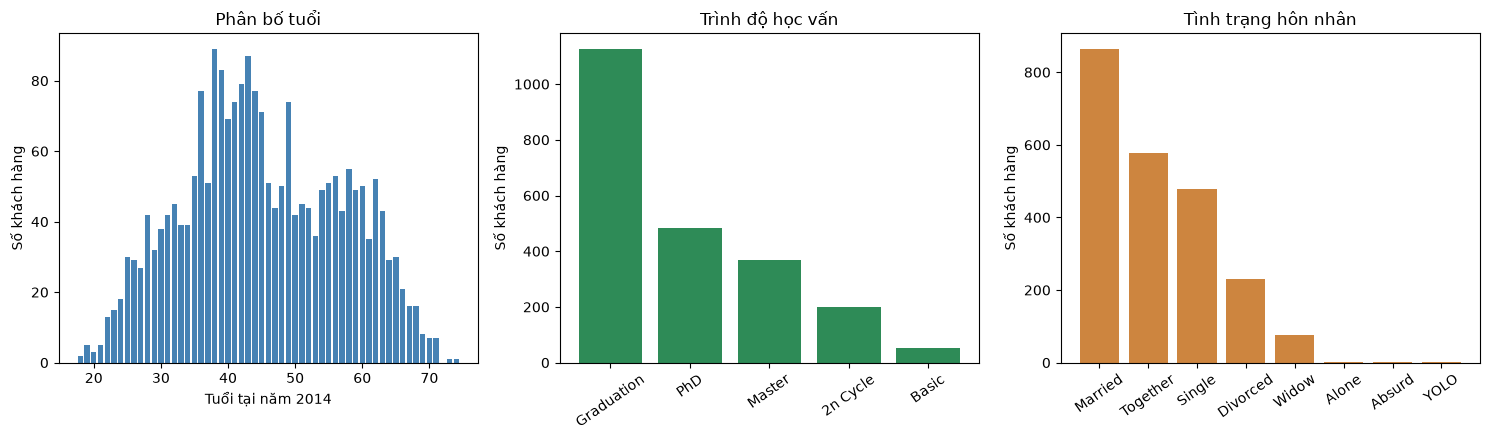

In [ ]:
plt.figure(figsize=(15, 4.5))
plt.subplot(1, 3, 1)
plt.bar(age_distribution.index, age_distribution.values, color="steelblue")
plt.title("Phân bố tuổi")
plt.xlabel("Tuổi tại năm 2014")
plt.ylabel("Số khách hàng")

plt.subplot(1, 3, 2)
plt.bar(education_counts.index, education_counts.values, color="seagreen")
plt.title("Trình độ học vấn")
plt.ylabel("Số khách hàng")
plt.xticks(rotation=35)

plt.subplot(1, 3, 3)
plt.bar(marital_counts.index, marital_counts.values, color="peru")
plt.title("Tình trạng hôn nhân")
plt.ylabel("Số khách hàng")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

**Nhận xét:** Nhóm tuổi 35–49 chiếm 46,02%, nhóm 50–64 chiếm 30,23%. Graduation có nhiều khách hàng nhất (1.126), Married là trạng thái hôn nhân phổ biến nhất (864).

<a id="phan-5-5"></a>
## 5.5. MỐI LIÊN HỆ GIỮA THU NHẬP VÀ TỔNG CHI TIÊU

Mỗi điểm là một khách hàng, với `Income` trên trục ngang và `Spent` trên trục dọc.
Vòng lặp vẽ lần lượt ba nhóm chi tiêu, mỗi nhóm dùng một màu và một nhãn trong chú giải.
Các dải màu xuất hiện vì nhóm được chia từ chính Spent; đây không phải bằng chứng về chất lượng phân cụm.
Hệ số Pearson bổ sung cách đọc biểu đồ. Tương quan không chứng minh quan hệ nhân quả.

Hệ số tương quan Pearson Income–Spent: 0.789


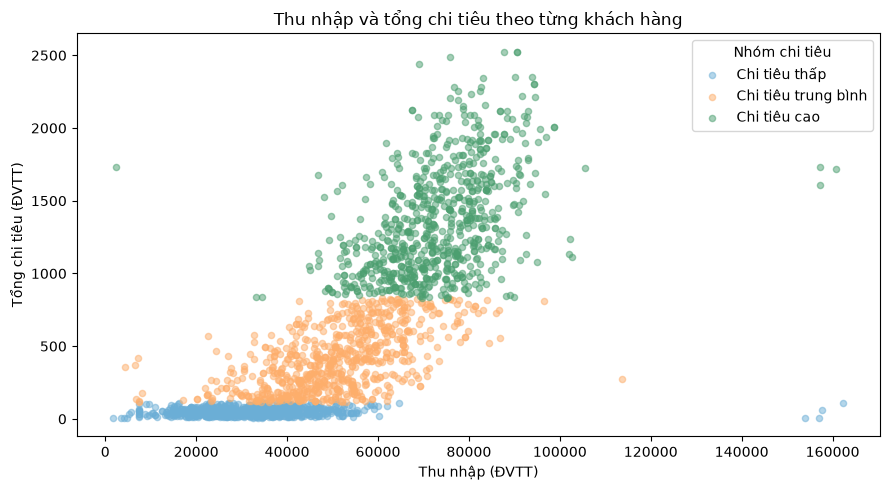

In [ ]:
income_spent_correlation = df_clean["Income"].corr(df_clean["Spent"])
print("Hệ số tương quan Pearson Income–Spent:", round(income_spent_correlation, 4))

plt.figure(figsize=(9, 5))
for i in range(3):
    group_data = df_clean[df_clean["Spending_Group"] == group_names[i]]
    plt.scatter(group_data["Income"], group_data["Spent"],
                color=group_colors[i], label=group_names[i], s=20, alpha=0.5)
plt.title("Thu nhập và tổng chi tiêu theo từng khách hàng")
plt.xlabel("Thu nhập (ĐVTT)")
plt.ylabel("Tổng chi tiêu (ĐVTT)")
plt.legend(title="Nhóm chi tiêu")
plt.tight_layout()
plt.show()

**Nhận xét:** Pearson khoảng 0,7890 cho thấy thu nhập và chi tiêu có mối liên hệ tuyến tính dương khá mạnh trong mẫu. Những hồ sơ thu nhập cao nhưng chi tiêu thấp vẫn được giữ và thể hiện trên hình.

<a id="phan-6"></a>
# 6. SO SÁNH NHÓM CHI TIÊU VÀ ĐỀ XUẤT MARKETING

Spending_Group đã được tạo cùng Spent tại mục 4.3. Phần này dùng nhóm có sẵn để so sánh mô tả; ngưỡng phụ thuộc phân bố mẫu và không phải kết quả thuật toán phân cụm.

<a id="phan-6-1"></a>
## 6.1. QUY MÔ, KHOẢNG CHI TIÊU VÀ PHẢN HỒI

Gộp theo `Spending_Group` để tính số khách hàng, khoảng chi tiêu, số phản hồi và tỷ lệ phản hồi.
`Response` là 0/1, nên tổng là số người phản hồi và trung bình nhân 100 là tỷ lệ trong nhóm.
Ví dụ, nhóm cao có 186 người phản hồi trên 745 người: `186 / 745 * 100 ≈ 24,97%`.
Chỉ làm tròn khi hiển thị bảng, giữ số đầy đủ khi tính toán.

In [ ]:
groups = df_clean.groupby("Spending_Group", observed=True)
group_summary = pd.DataFrame({
    "Số khách hàng": groups.size(),
    "Chi tiêu thấp nhất": groups["Spent"].min(),
    "Chi tiêu cao nhất": groups["Spent"].max(),
    "Số phản hồi": groups["Response"].sum(),
    "Tỷ lệ phản hồi (%)": groups["Response"].mean() * 100,
})
display(group_summary.round(2))

,Số khách hàng,Chi tiêu thấp nhất,Chi tiêu cao nhất,Số phản hồi,Tỷ lệ phản hồi (%)
Spending_Group,,,,,
Chi tiêu thấp,746,5,115,57,7.64
Chi tiêu trung bình,745,116,832,91,12.21
Chi tiêu cao,745,833,2525,186,24.97


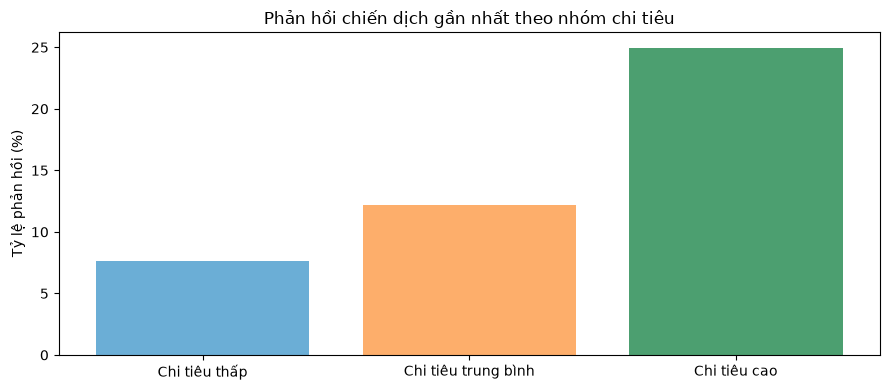

In [ ]:
plt.figure(figsize=(9, 4))
plt.bar(group_summary.index, group_summary["Tỷ lệ phản hồi (%)"], color=group_colors)
plt.title("Phản hồi chiến dịch gần nhất theo nhóm chi tiêu")
plt.ylabel("Tỷ lệ phản hồi (%)")
plt.tight_layout()
plt.show()

**Nhận xét:** Tỷ lệ phản hồi của nhóm thấp, trung bình và cao lần lượt là 7,64%, 12,21% và 24,97%. Sự khác biệt là kết quả mô tả trong mẫu, chưa chứng minh quan hệ nhân quả.

<a id="phan-6-2"></a>
## 6.2. ĐẶC ĐIỂM TỪNG NHÓM

So sánh tuổi, thu nhập, chi tiêu trung bình và tỷ lệ hộ có con. Các giá trị trung bình mô tả nhóm và không đại diện cho hành vi của mọi khách hàng trong nhóm.

In [ ]:
profile = groups[["Age", "Income", "Spent", "Is_Parent"]].mean()
profile["Is_Parent"] = profile["Is_Parent"] * 100
profile.columns = ["Tuổi trung bình", "Thu nhập trung bình (ĐVTT)",
                   "Chi tiêu trung bình (ĐVTT)", "Tỷ lệ hộ có con (%)"]
display(profile.round(2))

,Tuổi trung bình,Thu nhập trung bình (ĐVTT),Chi tiêu trung bình (ĐVTT),Tỷ lệ hộ có con (%)
Spending_Group,,,,
Chi tiêu thấp,41.86,32102.11,51.31,89.54
Chi tiêu trung bình,46.54,50908.00,413.94,84.70
Chi tiêu cao,46.91,72888.26,1353.46,40.27


<a id="phan-6-3"></a>
## 6.3. HƯỚNG THỬ NGHIỆM MARKETING

- **Thông điệp theo mức chi tiêu:** tỷ lệ phản hồi giữa ba nhóm khác nhau, nên có thể thử nội dung và giá trị ưu đãi phù hợp từng nhóm. Cần dữ liệu người được tiếp cận và nhóm so sánh để đánh giá.
- **Điểm tiếp xúc:** cửa hàng có tỷ trọng lượt mua lớn nhất trong mẫu, gợi ý xem xét thông tin sản phẩm và chương trình tại cửa hàng. Cần bổ sung chi phí, doanh thu và phản hồi theo kênh.
- **Nội dung sản phẩm:** rượu vang đóng góp tỷ trọng chi tiêu lớn, tạo cơ sở nghiên cứu nội dung giới thiệu và gợi ý mua phù hợp. Cần kiểm tra cơ cấu sản phẩm theo nhóm và biên lợi nhuận trước khi phân bổ nguồn lực.
- **Hồ sơ và hành vi:** kết hợp thu nhập với chi tiêu thực tế khi mô tả khách hàng; thu nhập riêng lẻ không đủ để giải thích hành vi từng người.

Những hướng trên cần được kiểm chứng qua chiến dịch bổ sung. Dữ liệu hiện tại chưa xác định thứ tự thời gian giữa chi tiêu và phản hồi, nên không dùng chênh lệch giữa nhóm để kết luận nguyên nhân hoặc đánh giá mô hình dự đoán.

<a id="phan-7"></a>
# 7. XUẤT VÀ ĐỐI CHIẾU DỮ LIỆU CHO DASHBOARD

<a id="phan-7-1"></a>
## 7.1. LỰA CHỌN THUỘC TÍNH XUẤT

Giữ đúng 23 cột: ID, Education, Marital_Status, Income, Age, Is_Parent, sáu cột sản phẩm,
ba cột kênh, năm trường AcceptedCmp, Response, Spent và Spending_Group.
Các thông tin gốc vẫn được giữ trong `df_raw`; tệp xuất lưu cùng thư mục notebook.

Đọc lại CSV rồi dùng `assert_frame_equal()` đối chiếu toàn bộ bảng.
CSV không giữ kiểu phân loại của Spending_Group, nên bỏ khác biệt về kiểu dữ liệu khi đối chiếu.
`index=False` tránh xuất thêm cột chỉ mục; `utf-8-sig` giữ nhãn tiếng Việt khi nạp vào Power BI.

CSV này dùng chung cho Streamlit và Power BI. Khi thay đổi dữ liệu thô, chạy lại notebook từ đầu để tạo CSV sạch mới. Streamlit tự đọc lại CSV sạch mỗi 30 giây khi phiên đang mở.


In [ ]:
powerbi_columns = (
    ["ID", "Education", "Marital_Status", "Income", "Age", "Is_Parent"]
    + product_columns + purchase_columns + campaign_columns
    + ["Response", "Spent", "Spending_Group"]
)
df_powerbi = df_clean[powerbi_columns].copy()
df_powerbi.to_csv("marketing_clean_powerbi.csv", index=False, encoding="utf-8-sig")

df_exported = pd.read_csv("marketing_clean_powerbi.csv", encoding="utf-8-sig")
pd.testing.assert_frame_equal(df_exported, df_powerbi.reset_index(drop=True),
                              check_dtype=False, check_categorical=False)
assert df_exported.shape == (len(df_clean), 23), "Số dòng hoặc số cột xuất chưa đúng."
print("Đã xuất marketing_clean_powerbi.csv:", df_exported.shape)
print("Đọc lại và đối chiếu toàn bộ dữ liệu: đạt")
display(df_exported.head())

Đã xuất marketing_clean_powerbi.csv: (2236, 23)
Đọc lại và đối chiếu toàn bộ dữ liệu: đạt


,ID,Education,Marital_Status,Income,Age,Is_Parent,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,AcceptedCmp1,AcceptedCmp2,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,Response,Spent,Spending_Group
0,5524,Graduation,Single,58138.0,57,0,635,88,546,172,88,88,8,10,4,0,0,0,0,0,1,1617,Chi tiêu cao
1,2174,Graduation,Single,46344.0,60,1,11,1,6,2,1,6,1,1,2,0,0,0,0,0,0,27,Chi tiêu thấp
2,4141,Graduation,Together,71613.0,49,0,426,49,127,111,21,42,8,2,10,0,0,0,0,0,0,776,Chi tiêu trung bình
3,6182,Graduation,Together,26646.0,30,1,11,4,20,10,3,5,2,0,4,0,0,0,0,0,0,53,Chi tiêu thấp
4,5324,PhD,Married,58293.0,33,1,173,43,118,46,27,15,5,3,6,0,0,0,0,0,0,422,Chi tiêu trung bình


<a id="phan-7-2"></a>
## 7.2. ĐỐI CHIẾU SỐ LIỆU VỚI BÁO CÁO

Các giá trị tham chiếu dưới đây thuộc bộ dữ liệu và báo cáo hiện tại. Đối chiếu ở trạng thái toàn bộ 2.236 khách hàng, chưa lọc. Khi thay đổi dữ liệu hoặc quy tắc xử lý, cần tính lại kết quả và cập nhật báo cáo.

In [ ]:
report_comparison = pd.DataFrame([
    ["Số khách hàng sạch", len(df_clean), 2236],
    ["Số cột xuất", df_exported.shape[1], 23],
    ["Tổng chi tiêu", df_clean["Spent"].sum(), 1354986],
    ["Thu nhập trung bình", round(df_clean["Income"].mean(), 2), 51957.24],
    ["Số phản hồi gần nhất", df_clean["Response"].sum(), 334],
    ["Tỷ lệ phản hồi gần nhất (%)", round(df_clean["Response"].mean() * 100, 2), 14.94],
    ["Tỷ trọng chi tiêu rượu vang (%)", round(product_totals["MntWines"] / product_totals.sum() * 100, 2), 50.19],
    ["Tỷ trọng lượt mua cửa hàng (%)", round(channel_totals["NumStorePurchases"] / channel_totals.sum() * 100, 2), 46.19],
    ["Phản hồi nhóm chi tiêu thấp (%)", round(group_summary.loc[group_names[0], "Tỷ lệ phản hồi (%)"], 2), 7.64],
    ["Phản hồi nhóm chi tiêu trung bình (%)", round(group_summary.loc[group_names[1], "Tỷ lệ phản hồi (%)"], 2), 12.21],
    ["Phản hồi nhóm chi tiêu cao (%)", round(group_summary.loc[group_names[2], "Tỷ lệ phản hồi (%)"], 2), 24.97],
    ["Pearson Income–Spent", round(income_spent_correlation, 4), 0.7890],
], columns=["Chỉ số", "Tính từ notebook", "Trong báo cáo"])
report_comparison["Khớp"] = report_comparison["Tính từ notebook"] == report_comparison["Trong báo cáo"]
display(report_comparison)
assert report_comparison["Khớp"].all(), "Có số liệu khác báo cáo."

,Chỉ số,Tính từ notebook,Trong báo cáo,Khớp
0,Số khách hàng sạch,2236.000,2236.000,True
1,Số cột xuất,23.000,23.000,True
2,Tổng chi tiêu,1354986.000,1354986.000,True
3,Thu nhập trung bình,51957.240,51957.240,True
4,Số phản hồi gần nhất,334.000,334.000,True
5,Tỷ lệ phản hồi gần nhất (%),14.940,14.940,True
6,Tỷ trọng chi tiêu rượu vang (%),50.190,50.190,True
7,Tỷ trọng lượt mua cửa hàng (%),46.190,46.190,True
8,Phản hồi nhóm chi tiêu thấp (%),7.640,7.640,True
9,Phản hồi nhóm chi tiêu trung bình (%),12.210,12.210,True


<a id="phan-8"></a>
# 8. KẾT LUẬN VÀ HẠN CHẾ

## Kết luận

Quy trình đi từ 2.240 hồ sơ và 29 thuộc tính ban đầu đến 2.236 hồ sơ sạch; 24 giá trị Income được bổ sung và bốn hồ sơ bất thường được loại. Tệp phục vụ Power BI gồm 23 cột đã kiểm tra và đọc lại sau xuất.

Tổng chi tiêu là 1.354.986 ĐVTT; rượu vang chiếm 50,19%. Cửa hàng chiếm 46,19% lượt mua qua ba kênh. Tỷ lệ phản hồi gần nhất là 14,94%; ba nhóm chi tiêu thấp, trung bình và cao có tỷ lệ lần lượt 7,64%, 12,21% và 24,97%. Thu nhập và Spent có tương quan Pearson dương khoảng 0,7890 trong mẫu. Các bảng hồ sơ và biểu đồ cung cấp căn cứ đối chiếu với hai dashboard.

## Hạn chế

- Đơn vị tiền tệ chưa được xác minh; dữ liệu thiếu lịch sử chi tiết theo giao dịch, nội dung chiến dịch, chi phí và lợi nhuận.
- Income được bổ sung bằng trung vị là giá trị ước lượng; quy tắc loại bất thường và ngưỡng phân vị có thể ảnh hưởng kết quả.
- Tỷ lệ chiến dịch tính trên toàn bộ hồ sơ, vì thiếu số người thực sự được tiếp cận.
- Chia nhóm theo Spent là phân nhóm mô tả. Chênh lệch phản hồi và tương quan không chứng minh quan hệ nhân quả hoặc khả năng dự đoán.
- Khi sử dụng bộ lọc Power BI, cần kiểm tra số khách hàng và mẫu số của tỷ lệ trước khi so sánh.